In [9]:
library(ggplot2)
library(dplyr)
library(readr)
library(broom)

In [10]:
files <- c("7.41" = "7.41dota2.csv", "7.42" = "7.42dota2.csv")
output_dir <- "patch_results"
dir.create(output_dir, showWarnings = FALSE)
medal_names <- c("Herald", "Guardian", "Crusader", "Archon", "Legend", "Ancient", "Divine", "Immortal")
medal_groups <- c(medal_names[1:6], "Divine / Immortal")
rank_codes <- as.vector(outer(1:5, 10 * (1:7), "+"))
valid_rank_codes <- c(rank_codes, 80L)
min_duration_seconds <- 1200L
duration_bands <- c("20 to <30", "30 to <40", "40+")
rank_bands <- c("Herald to Crusader", "Archon to Ancient", "Divine / Immortal")
match_columns <- c("match_id", "start_time", "duration", "lobby_type", "game_mode",
                   "radiant_win", "avg_rank_tier", "num_rank_tier")

read_sample <- function(path) {
  raw <- read_csv(path, progress = FALSE, col_types = cols(
    .default = col_character(), start_time = col_double(), duration = col_double(),
    lobby_type = col_integer(), avg_rank_tier = col_integer()
  ))
  if (!all(match_columns %in% names(raw))) stop("Missing match columns in ", path)
  ranked <- filter(raw, lobby_type == 7)
  long_enough <- filter(ranked, is.finite(duration), duration >= min_duration_seconds)
  eligible <- long_enough |>
    filter(avg_rank_tier %in% valid_rank_codes, grepl("^[1-9][0-9]*$", match_id),
           tolower(trimws(radiant_win)) %in% c("true", "false", "1", "0")) |>
    distinct()
  if (!nrow(eligible) || anyDuplicated(eligible$match_id)) {
    stop("Empty sample or conflicting match IDs in ", path)
  }
  list(data = eligible,
       audit = tibble(csv_rows = nrow(raw), ranked = nrow(ranked), ranked_20min = nrow(long_enough)))
}

samples <- lapply(files, read_sample)
audit <- bind_rows(lapply(samples, "[[", "audit"), .id = "patch")
matches <- bind_rows(lapply(samples, function(s) select(s$data, all_of(match_columns))), .id = "patch") |>
  mutate(patch = factor(patch, levels = names(files)),
         radiant_win = tolower(trimws(radiant_win)) %in% c("true", "1"),
         duration_min = duration / 60, medal_id = avg_rank_tier %/% 10L,
         medal_group = factor(medal_groups[pmin(medal_id, 7L)], levels = medal_groups),
         duration_band = cut(duration_min, c(20, 30, 40, Inf), duration_bands, right = FALSE),
         rank_band = cut(medal_id, c(0, 3, 6, 8), rank_bands))
if (anyDuplicated(matches$match_id)) stop("The samples have overlapping match IDs.")
for (patch_name in names(samples)) {
  write_csv(samples[[patch_name]]$data, file.path(output_dir, paste0(patch_name, "_ranked.csv")))
}

In [11]:
#sample overview
coverage <- matches |>
  group_by(patch) |>
  summarise(n = n(), radiant_wins = sum(radiant_win), dire_wins = n - radiant_wins,
            radiant_pct = 100 * mean(radiant_win), dire_pct = 100 - radiant_pct,
            first_utc = format(as.POSIXct(min(start_time), origin = "1970-01-01", tz = "UTC"), tz = "UTC"),
            last_utc = format(as.POSIXct(max(start_time), origin = "1970-01-01", tz = "UTC"), tz = "UTC"),
            mean_min = mean(duration_min), median_min = median(duration_min),
            min_min = min(duration_min), max_min = max(duration_min),
            matches_80_plus = sum(duration_min >= 80),
            mean_code = rank_codes[floor(mean(match(pmin(avg_rank_tier, 75), rank_codes)) + 0.5)],
            mean_medal = paste(medal_names[mean_code %/% 10], mean_code %% 10), .groups = "drop") |>
  select(-mean_code) |> left_join(audit, by = "patch") |>
  relocate(csv_rows, ranked, ranked_20min, .after = patch)
write_csv(coverage, file.path(output_dir, "sample_overview.csv"))
overview <- as.data.frame(t(as.data.frame(coverage[,-1])), stringsAsFactors = FALSE)
names(overview) <- as.character(coverage$patch)
print(overview)

                               7.41                7.42
csv_rows                    1029119              500000
ranked                       943326              500000
ranked_20min                 938598              500000
n                            938598              500000
radiant_wins                 497596              252781
dire_wins                    441002              247219
radiant_pct                53.01482            50.55620
dire_pct                   46.98518            49.44380
first_utc       2026-09-13 07:17:31 2026-11-22 19:30:58
last_utc        2026-09-23 06:48:18 2026-11-23 23:33:38
mean_min                   41.16510            41.96212
median_min                 40.10000            40.68333
min_min                          20                  20
max_min                    130.1167            133.9167
matches_80_plus                1713                1584
mean_medal                 Legend 1            Legend 2


In [12]:
# At p = 0.5 the exact two-sided binomial p-value is twice the smaller tail, capped at one.
# Work in log space because the result for patch 7.41 is too small for a numeric double.
wins <- coverage$radiant_wins
n <- coverage$n
log_within <- pmin(0, log(2) + pbinom(pmin(wins, n - wins), n, 0.5, log.p = TRUE))
between <- tidy(prop.test(wins, n, correct = FALSE))
log_between <- pchisq(between$statistic, between$parameter, lower.tail = FALSE, log.p = TRUE)
format_p <- function(log_p) {
  exponent <- floor(log_p / log(10))
  ifelse(log_p >= log(0.001), sprintf("%.4g", exp(log_p)),
         sprintf("%.4fe%d", exp(log_p - exponent * log(10)), as.integer(exponent)))
}
p_values <- tibble(
  comparison = c("7.41 Radiant vs 50%", "7.42 Radiant vs 50%", "7.41 vs 7.42 Radiant"),
  p_value = format_p(c(log_within, log_between))
)
print(p_values)
write_csv(p_values, file.path(output_dir, "overall_p_values.csv"))

# A tibble: 3 × 2
  comparison           p_value    
  <chr>                <chr>      
1 7.41 Radiant vs 50%  5.2062e-744
2 7.42 Radiant vs 50%  3.7051e-15 
3 7.41 vs 7.42 Radiant 7.1206e-174


In [13]:
chart_counts <- function(group, kind) {
  matches |> group_by(patch, stratum = as.character({{ group }})) |>
    summarise(n = n(), wins = sum(radiant_win), .groups = "drop") |> mutate(comparison = kind)
}
rates <- bind_rows(chart_counts("All matches", "Overall"),
                   chart_counts(duration_band, "Duration"), chart_counts(rank_band, "Rank")) |>
  rowwise() |>
  mutate(tidy(binom.test(wins, n)) |> select(radiant_rate = estimate, lo = conf.low, hi = conf.high)) |>
  ungroup() |> mutate(dire_rate = 1 - radiant_rate)

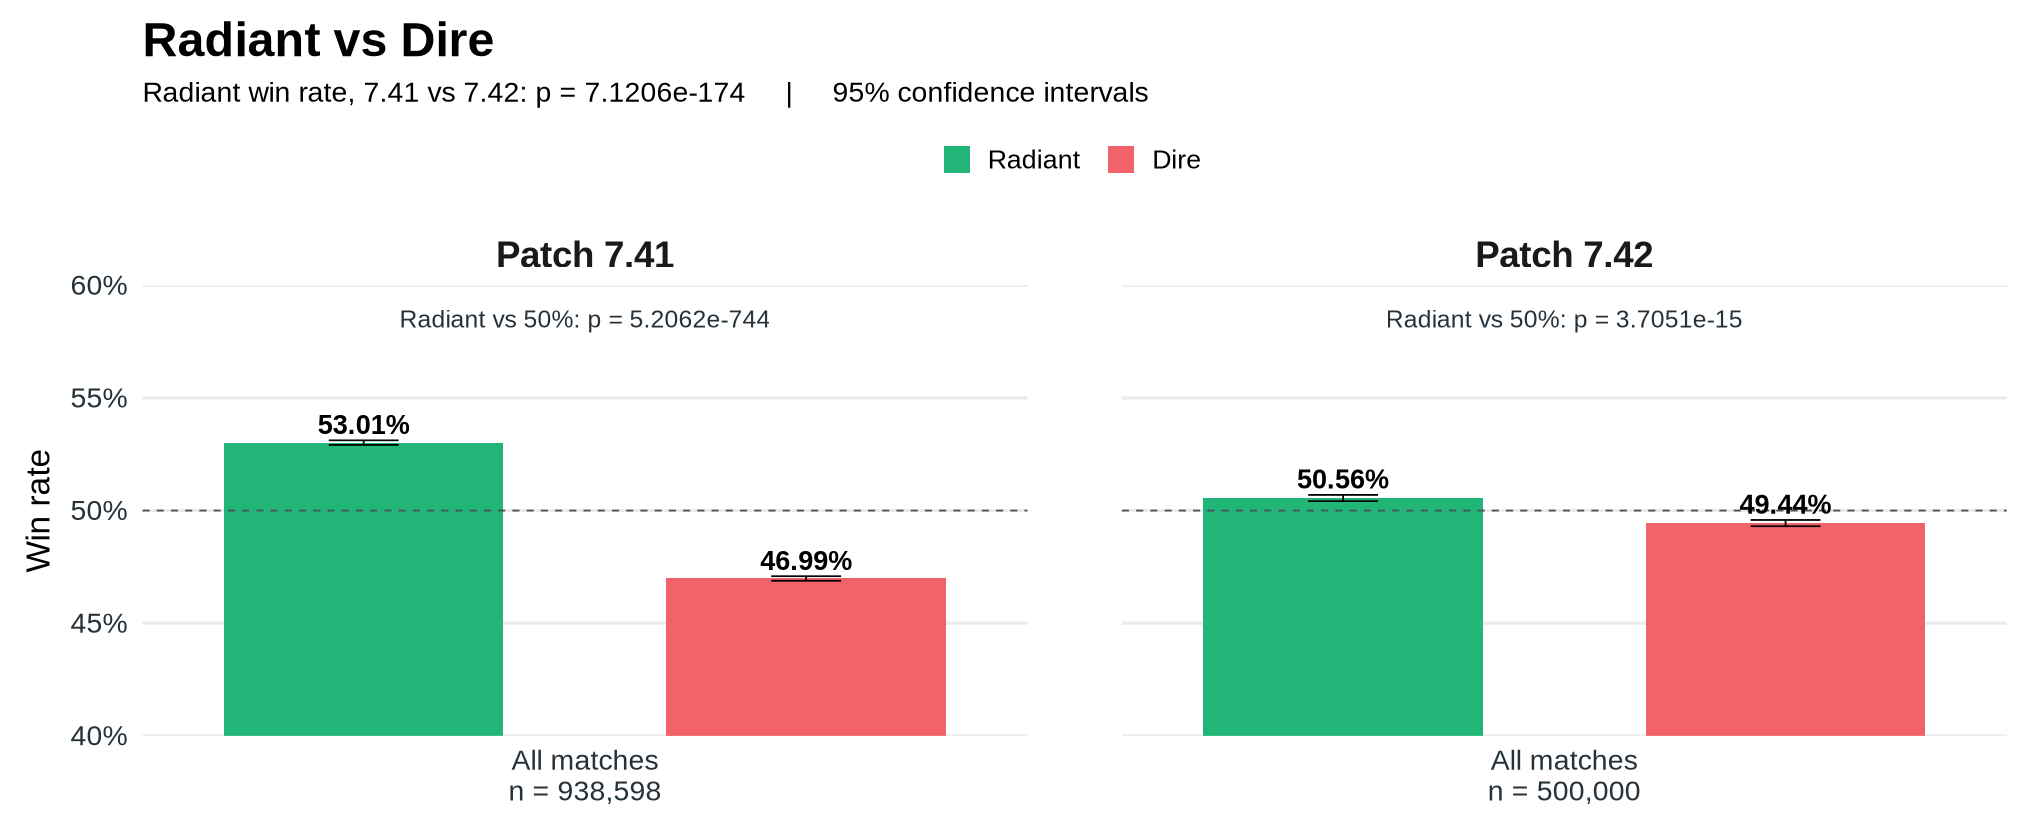

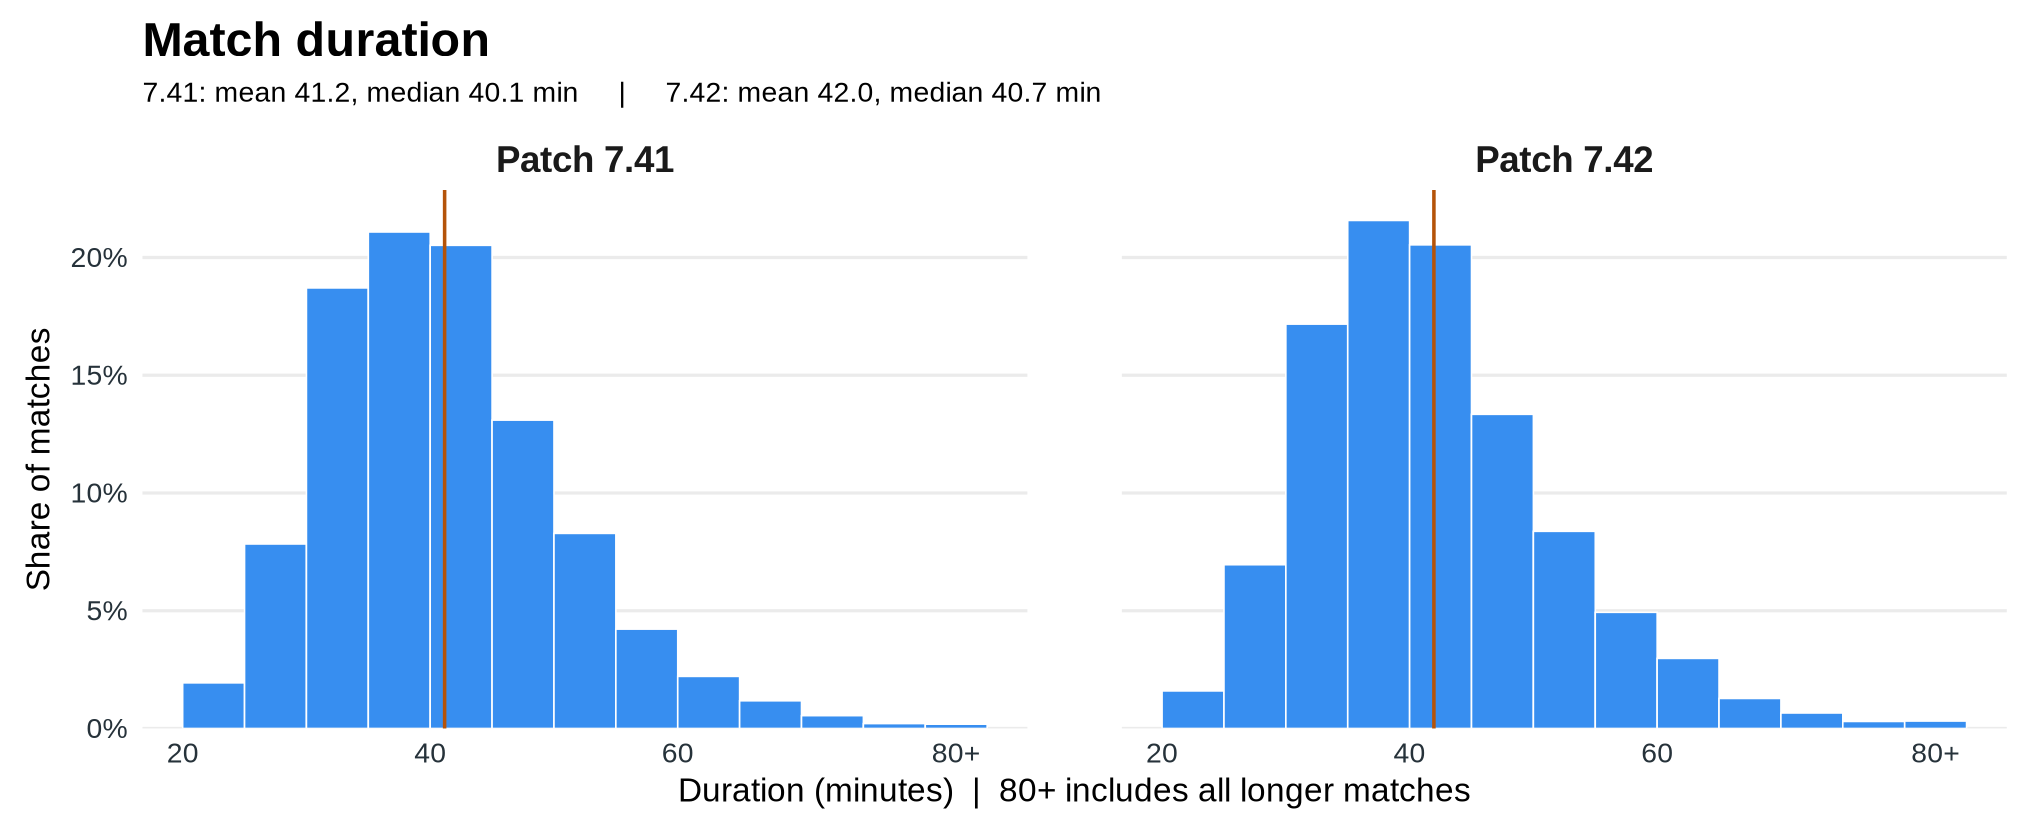

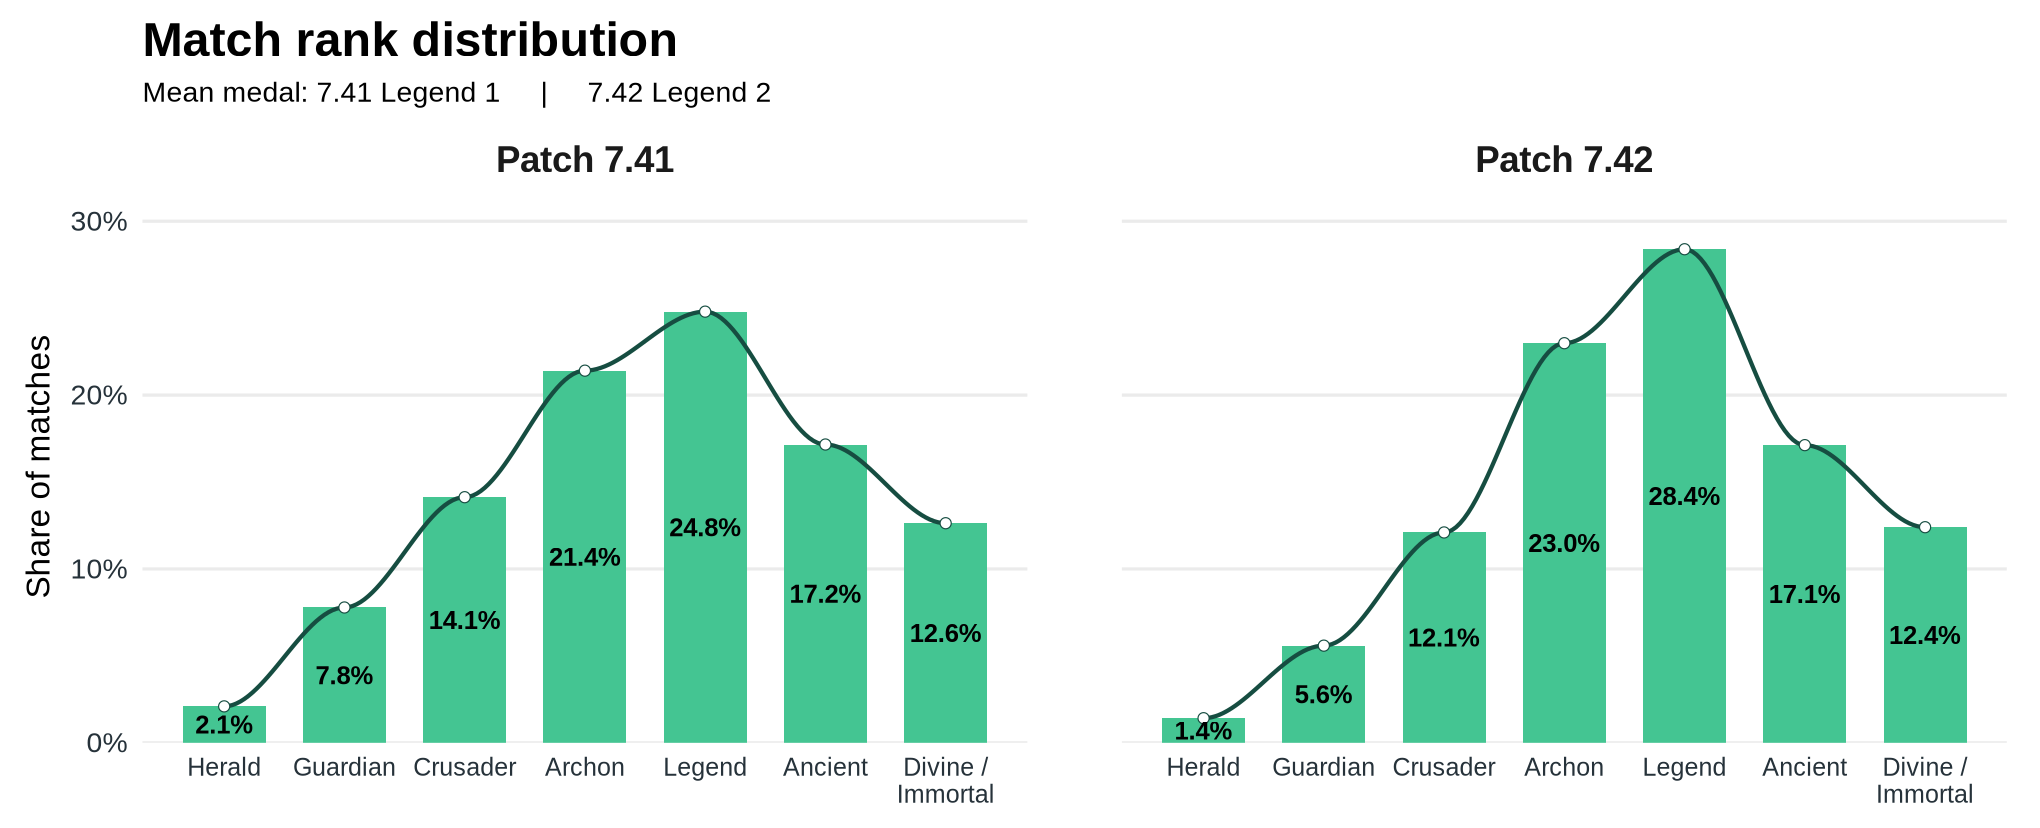

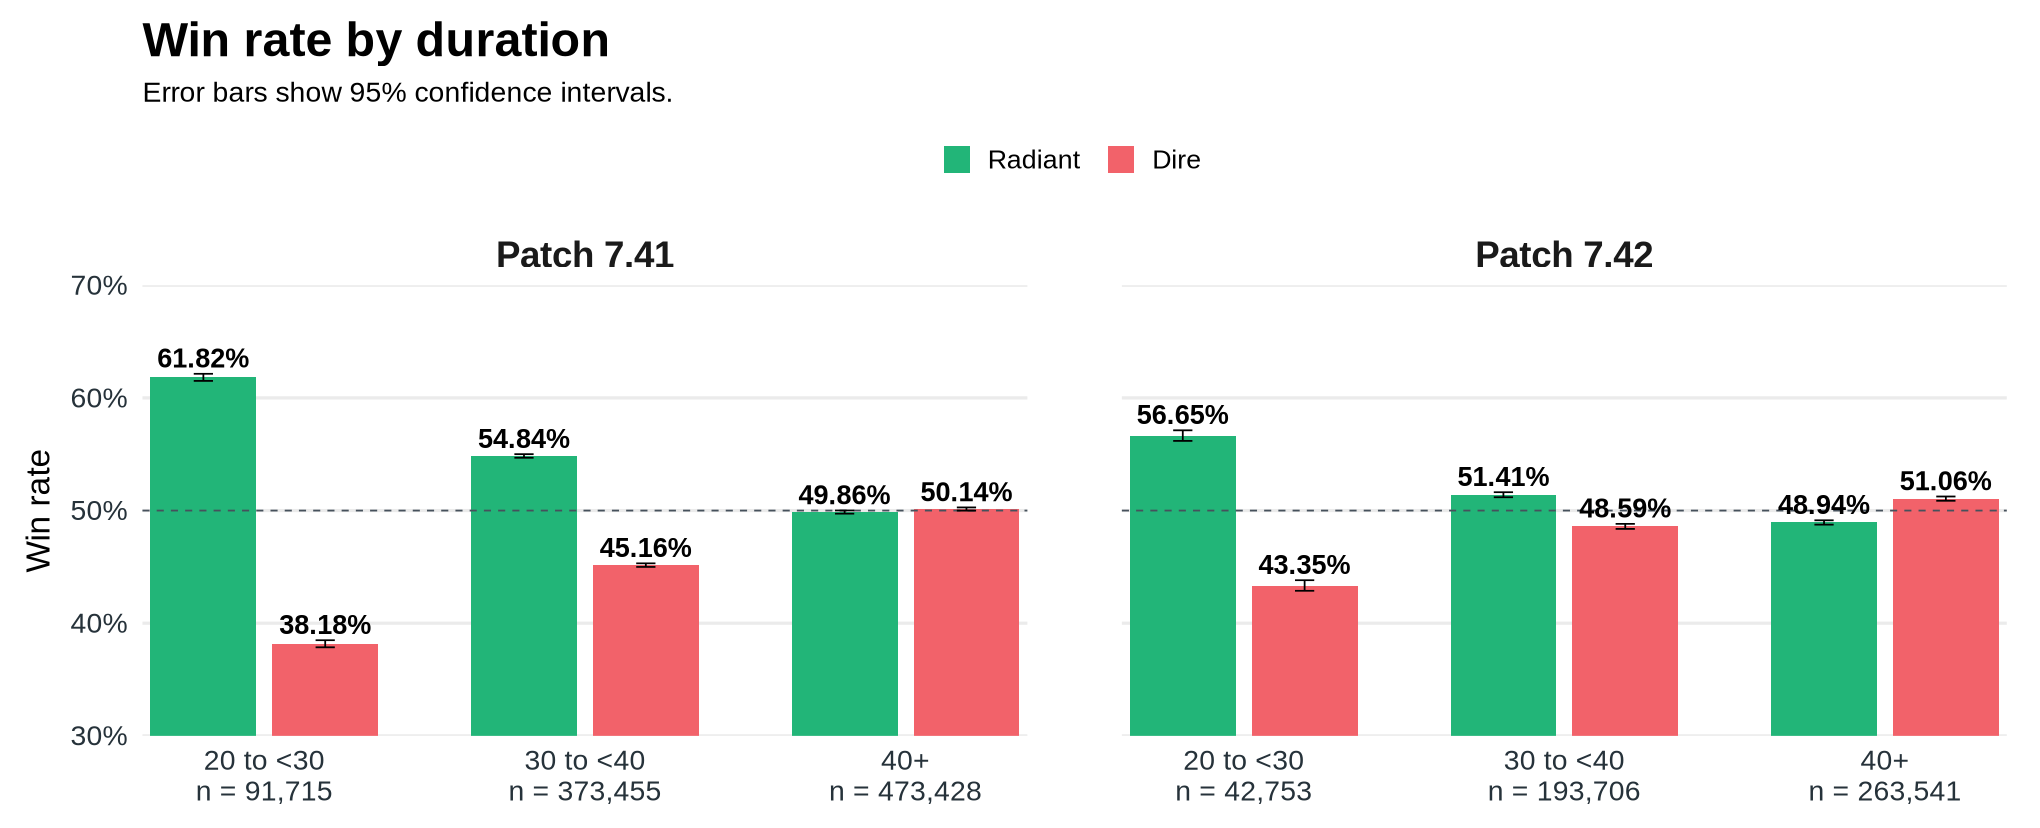

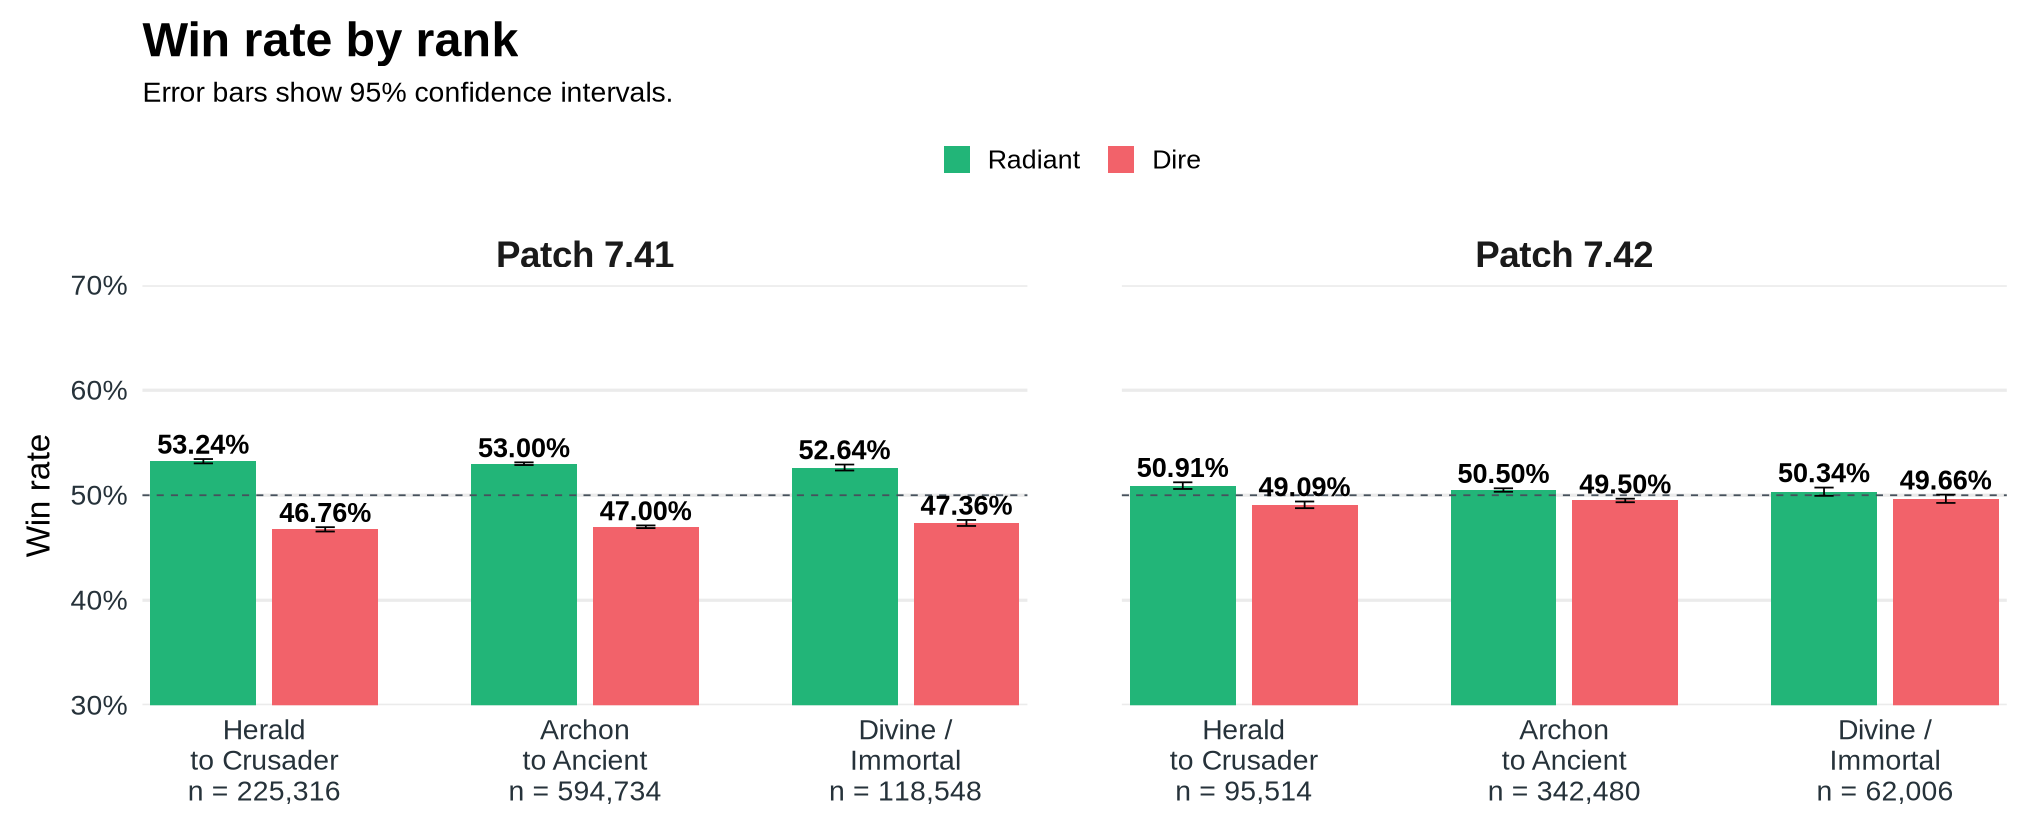

In [16]:
options(repr.plot.width = 17, repr.plot.height = 6.9, repr.plot.res = 120)
pct <- function(x) paste0(round(100 * x), "%")
wrap_rank <- function(x) sub(" / ", " /\n", sub(" to ", "\nto ", x, fixed = TRUE), fixed = TRUE)
patch_labels <- labeller(patch = function(x) paste("Patch", x))
common <- theme_minimal(base_size = 20) +
  theme(plot.title = element_text(size = 29, face = "bold"),
        plot.subtitle = element_text(size = 17, margin = margin(b = 12)),
        strip.text = element_text(size = 22, face = "bold"),
        axis.text = element_text(size = 17, colour = "#26323A"), legend.position = "top",
        panel.spacing.x = grid::unit(2, "cm"), panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(), plot.margin = margin(14, 20, 12, 16))
paired <- facet_wrap(~ patch, nrow = 1, labeller = patch_labels)
side_colours <- c(Radiant = "#22B578", Dire = "#F2626A")

win_chart <- function(kind, groups, title) {
  z <- rates |> filter(comparison == kind) |> arrange(match(stratum, groups), patch) |>
    mutate(tick = paste0(if (kind == "Rank") wrap_rank(stratum) else stratum, "\nn = ", format(n, big.mark = ",", trim = TRUE)),
           tick = factor(tick, levels = unique(tick)))
  bars <- bind_rows(
    transmute(z, patch, tick, side = "Radiant", rate = radiant_rate, low = lo, high = hi),
    transmute(z, patch, tick, side = "Dire", rate = dire_rate, low = 1 - hi, high = 1 - lo)
  ) |> mutate(side = factor(side, levels = names(side_colours)))
  overall <- kind == "Overall"
  limits <- if (overall) c(0.40, 0.60) else c(0.30, 0.70)
  bar_width <- if (overall) 0.48 else 0.66
  note <- "Error bars show 95% confidence intervals."
  if (overall) {
    p_lookup <- setNames(p_values$p_value, p_values$comparison)
    z$p_label <- paste0("Radiant vs 50%: p = ", p_lookup[paste(z$patch, "Radiant vs 50%")])
    note <- paste0("Radiant win rate, 7.41 vs 7.42: p = ",
                   p_lookup[["7.41 vs 7.42 Radiant"]], "     |     95% confidence intervals")
  }
  dodge <- position_dodge(width = 0.76)
  chart <- ggplot(bars, aes(tick, rate, fill = side, group = side)) +
    geom_col(position = dodge, width = bar_width) +
    geom_hline(yintercept = 0.5, linetype = "dashed", colour = "#46515C") +
    geom_errorbar(aes(ymin = low, ymax = high), position = dodge, width = 0.12) +
    geom_text(aes(y = pmin(limits[2] - 0.0375 * diff(limits),
                           pmax(limits[1] + 0.0425 * diff(limits), high + 0.035 * diff(limits))), label = sprintf("%.2f%%", 100 * rate)),
              position = dodge, size = 5.7, fontface = "bold") +
    facet_wrap(~ patch, nrow = 1, scales = "free_x", labeller = patch_labels) +
    scale_fill_manual(values = side_colours) +
    scale_y_continuous(breaks = seq(limits[1], limits[2], length.out = 5), labels = pct) +
    coord_cartesian(ylim = limits, expand = FALSE) +
    labs(title = title, subtitle = note,
         x = NULL, y = "Win rate", fill = NULL) + common
  if (overall) {
    chart <- chart + geom_text(data = z, aes(x = tick, label = p_label), y = 0.585,
                               inherit.aes = FALSE, size = 5.2, colour = "#26323A")
  }
  chart
}

bins <- matches |> count(patch, start = pmin(80, 5 * floor(duration_min / 5))) |>
  group_by(patch) |> mutate(share = n / sum(n)) |> ungroup()
duration_note <- with(coverage, paste(sprintf("%s: mean %.1f, median %.1f min", patch,
                                              mean_min, median_min), collapse = "     |     "))
duration_plot <- ggplot(bins, aes(start + 2.5, share)) +
  geom_col(width = 5, fill = "#378EF0", colour = "white", linewidth = 0.45) +
  geom_vline(data = coverage, aes(xintercept = mean_min), colour = "#B45309", linewidth = 1) +
  scale_x_continuous(breaks = c(20, 40, 60, 82.5), labels = c("20", "40", "60", "80+")) +
  scale_y_continuous(labels = pct, expand = expansion(mult = c(0, 0.06))) +
  labs(title = "Match duration", subtitle = duration_note,
       x = "Duration (minutes)  |  80+ includes all longer matches",
       y = "Share of matches") +
  paired + common

medals <- matches |> count(patch, medal_group, .drop = FALSE) |> group_by(patch) |>
  mutate(x = as.integer(medal_group), share = n / sum(n)) |> arrange(x, .by_group = TRUE) |> ungroup()
# A smooth curve through the seven observed shares, with no overshoot between medals.
curve_data <- medals |> group_by(patch) |>
  reframe(x_curve = seq(min(x), max(x), length.out = 181),
          share_curve = splinefunH(x, share, rep(0, length(x)))(x_curve))
medal_plot <- ggplot(medals, aes(x, share)) +
  geom_col(width = 0.69, fill = "#44C592") +
  geom_line(data = curve_data, aes(x_curve, share_curve), colour = "#164D41", linewidth = 1.2) +
  geom_point(shape = 21, size = 2.8, fill = "white", colour = "#164D41") +
  geom_text(aes(y = share / 2, label = sprintf("%.1f%%", 100 * share)), size = 5.4, fontface = "bold") +
  scale_x_continuous(breaks = seq_along(levels(matches$medal_group)), labels = wrap_rank(levels(matches$medal_group))) +
  scale_y_continuous(labels = pct, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Match rank distribution", x = NULL, y = "Share of matches",
       subtitle = paste("Mean medal:", paste(coverage$patch, coverage$mean_medal, collapse = "     |     "))) +
  paired + common + theme(axis.text.x = element_text(angle = 0, hjust = 0.5, size = 15))

plots <- list(overall_win_rate = win_chart("Overall", "All matches", "Radiant vs Dire"),
              duration_distribution = duration_plot, rank_distribution = medal_plot,
              win_rate_by_duration = win_chart("Duration", levels(matches$duration_band), "Win rate by duration"),
              win_rate_by_rank = win_chart("Rank", levels(matches$rank_band), "Win rate by rank"))
for (name in names(plots)) {
  print(plots[[name]])
  ggsave(file.path(output_dir, paste0(name, ".png")), plots[[name]],
         width = 17, height = 6.9, dpi = 180, bg = "white")
}